# Binary Logistic Regression

This notebook evaluates whether logistic regression can differentiate normal (NORM) ECGs from ECGs that have myocardial infarction (MI) using the PTB-XL dataset. It compares 60 ECG-derived statistical features with principal component analysis (PCA). 

My goal of this notebook is to be able to answer these guiding questions: 

1. How accurately can logistic regression distinguish normal ECGs from MI-related ECGs?

2. Can PCA reduce the number of features while preserving predictive performance?

3. How does the number of principal components affect classification performance?

4. Do normal and MI-related ECGs separate visibly along PC1 and PC2?

## 1. Loading and verifying the processed data 

I will start with the preprocessed PTB-XL recordings. Each of the 10-second ECGs contains 1000 time points (samples) from 12 leads. The waveform array, diagnostic labels, demographic table, and official split assignments (training, validation, testing) must have matching ECG IDs and row order. I'm completing these checks now so that I do not accidentally pair a waveform with the wrong diagnosis. 

*(Side note: I will open the waveforms with `mmap_mode='r'` so that the full dataset does not need to be loaded into RAM)*

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    f1_score, recall_score, confusion_matrix, roc_curve
)

# would need to change this path to your local path
DATA_DIR = Path("/work/users/s/b/sbalaji/BIOS784_Project/data/processed")
X = np.load(DATA_DIR / "waveforms.npy", mmap_mode="r")
recording_ids = np.load(DATA_DIR / "recording_ids.npy")
labels = pd.read_csv(DATA_DIR / "labels.csv")
predictors = pd.read_csv(DATA_DIR / "predictors.csv")
splits = pd.read_csv(DATA_DIR / "splits.csv")

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
assert np.array_equal(labels.ecg_id.to_numpy(), recording_ids)
assert np.array_equal(predictors.ecg_id.to_numpy(), recording_ids)
assert np.array_equal(splits.ecg_id.to_numpy(), recording_ids)

df = (labels.merge(predictors[["ecg_id", "age", "sex"]], on="ecg_id", validate="one_to_one")
            .merge(splits[["ecg_id", "partition"]], on="ecg_id", validate="one_to_one"))
assert np.array_equal(df.ecg_id.to_numpy(), recording_ids)

print("ECG waveforms:", X.shape)
print("Diagnostic labels:", CLASSES)
print("Official partitions:", df.partition.value_counts().to_dict())

ECG waveforms: (21799, 1000, 12)
Diagnostic labels: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Official partitions: {'train': 17418, 'test': 2198, 'validation': 2183}


## 2. Defining the normal versus MI cohort 

Here, we ultimately want to see whether an ECG is normal (0) or if it has MI-related abnormalities (1). Therefore, I'm including recordings labeled NORM but not MI, or MI but not NORM (recordings that are labeled both or neither are excluded). *It is important to note that an MI recording can still have other abnormal diagnostic labels*

Instead of creating a new random split, I'm keeping the original training, validation, and test partitions in the data. This gives 11973 training, 1495 validation, ad 1513 test ECGs. 

In [2]:
# Definimg a binary NORM vs MI cohort
norm_only = (df["NORM"] == 1) & (df["MI"] == 0)
mi_only = (df["MI"] == 1) & (df["NORM"] == 0)

binary_eligible = norm_only | mi_only

# Binary outcome is either 0 = NORM or 1 = MI
y_binary = df["MI"].to_numpy(dtype=int)

# Keeping the original train/validation/test partitions
binary_train_idx = np.flatnonzero(
    binary_eligible & df["partition"].eq("train")
)

binary_val_idx = np.flatnonzero(
    binary_eligible & df["partition"].eq("validation")
)

binary_test_idx = np.flatnonzero(
    binary_eligible & df["partition"].eq("test")
)

# Summarising class counts
for name, idx in [
    ("Training", binary_train_idx),
    ("Validation", binary_val_idx),
    ("Test", binary_test_idx)
]:
    labels_subset = y_binary[idx]

    print(f"\n{name}:")
    print("Total:", len(idx))
    print("Normal:", np.sum(labels_subset == 0))
    print("MI:", np.sum(labels_subset == 1))


Training:
Total: 11973
Normal: 7595
MI: 4378

Validation:
Total: 1495
Normal: 955
MI: 540

Test:
Total: 1513
Normal: 963
MI: 550


### Checking patient-disjointness across partitions 

Another note is that multiple ECGs can belong to the same patient. If a patient's ECG appeared both in training and testing, then the performance of the model could be inflated with patient specific similarities. Therefore, I'm checking that the official partitions have zero overlapping patient IDs. 

In [3]:
patient_ids = predictors["patient_id"].to_numpy()
groups = {
    part: set(patient_ids[df.partition.eq(part).to_numpy()])
    for part in ["train", "validation", "test"]
}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = len(groups[a] & groups[b])
    print(f"{a} / {b} patient overlap: {overlap}")
    assert overlap == 0

train / validation patient overlap: 0
train / test patient overlap: 0
validation / test patient overlap: 0


## 3. Extracting ECG summary features and fitting the baseline model 

Instead of using all 12000 waveform values directly, I'm summarising each lead with the mean, standard deviation, minimum, maximum, and root square mean (RMS). This creates 60 features that describe the signal's overall amplitude and variability. 

Each of the derived features is standardised using the training-set mean and standard deviation. Logistic regression uses these scaled features to estimate the probability of MI, and validation AUROC and AUPRC says how well it distinguishes the two groups without using the held-out test set. 

In [4]:
def extract_ecg_features(waveforms):
    """Extracting 5 statistical features from each of 12 ECG leads."""
    features = []

    for batch_start in range(0, len(waveforms), 1000):
        batch = np.asarray(
            waveforms[batch_start:batch_start + 1000],
            dtype=np.float32
        )

        mean = batch.mean(axis=1)
        std = batch.std(axis=1)
        minimum = batch.min(axis=1)
        maximum = batch.max(axis=1)
        rms = np.sqrt(np.mean(batch**2, axis=1))

        batch_features = np.concatenate(
            [mean, std, minimum, maximum, rms],
            axis=1
        )

        features.append(batch_features)

    return np.vstack(features)

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Selecting existing ECG-derived features for the binary cohort
X_binary_train = extract_ecg_features(X[binary_train_idx])
X_binary_val = extract_ecg_features(X[binary_val_idx])

y_binary_train = y_binary[binary_train_idx]
y_binary_val = y_binary[binary_val_idx]

# Standardising using binary training data only
binary_scaler = StandardScaler()

X_binary_train_scaled = binary_scaler.fit_transform(X_binary_train)
X_binary_val_scaled = binary_scaler.transform(X_binary_val)

# Training logistic regression
binary_lr = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

binary_lr.fit(X_binary_train_scaled, y_binary_train)

# Predicting probabilities
train_probs = binary_lr.predict_proba(X_binary_train_scaled)[:, 1]
val_probs = binary_lr.predict_proba(X_binary_val_scaled)[:, 1]

print("Binary NORM vs MI Logistic Regression")
print("------------------------------------")
print(f"Training AUROC: {roc_auc_score(y_binary_train, train_probs):.4f}")
print(f"Validation AUROC: {roc_auc_score(y_binary_val, val_probs):.4f}")
print(f"Validation AUPRC: {average_precision_score(y_binary_val, val_probs):.4f}")
print(f"Iterations: {binary_lr.n_iter_[0]}")

Binary NORM vs MI Logistic Regression
------------------------------------
Training AUROC: 0.8402
Validation AUROC: 0.8473
Validation AUPRC: 0.7705
Iterations: 130


The training and validation should be reasonably close because otherwise, if the training score was much larger, that would suggest overfitting. Here, the training AUROC is 0.8402 and the validation AUROC is 0.8473, which is expected. Additionally, the validation AUPRC is 0.7705. 

## 4. Fitting logistic regression after PCA 

PCA constructs new mutually orthogonal features that explain variation in the standardised ECG summaries. I'm choosing the smallest number of components explaining at least 95% of the training-set cariance, and then fitting a new logistic regression on those components. Since PCA and logistic regression are both fitted on the training data, the validation recordings are transformed without refitting. 

Using PCA tests whether a more compact representation of the data retains information that is useful for MI classification. It is important to know that high explained variance does not guarantee high predictive performance because the directions with the most overall variation are not necessarily the ones that can distinguish MI from normal ECGs. 

In [6]:
from sklearn.decomposition import PCA

# Fitting PCA using binary training data only
binary_pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

X_binary_train_pca = binary_pca.fit_transform(
    X_binary_train_scaled
)

X_binary_val_pca = binary_pca.transform(
    X_binary_val_scaled
)

# Training logistic regression on PCA features
binary_lr_pca = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

binary_lr_pca.fit(
    X_binary_train_pca,
    y_binary_train
)

# Evaluating validation performance
val_probs_pca = binary_lr_pca.predict_proba(
    X_binary_val_pca
)[:, 1]

print("PCA + Binary Logistic Regression")
print("--------------------------------")
print("Number of components:", binary_pca.n_components_)
print(
    "Explained variance:",
    round(binary_pca.explained_variance_ratio_.sum(), 4)
)
print(
    "Validation AUROC:",
    round(roc_auc_score(y_binary_val, val_probs_pca), 4)
)
print(
    "Validation AUPRC:",
    round(average_precision_score(y_binary_val, val_probs_pca), 4)
)
print("Iterations:", binary_lr_pca.n_iter_[0])

PCA + Binary Logistic Regression
--------------------------------
Number of components: 19
Explained variance: 0.9508
Validation AUROC: 0.8421
Validation AUPRC: 0.7614
Iterations: 20


Here, the 95% variance selected 19 components explaining 95.08% of the training variance. The validation AUROC is 0.8421, which is only slightly below the original result of 0.8473. Overall, this supports PCA as a compact alternative, but does not suggest that it improves performance. 

## 5. Examining the number of principal components 

In order to understand the dimensionality-performance tradeoff, I will now repeat logistic regression using 2, 5, 10, 15, 19, 25, 30, 40, 50, or 60 PCs. For each of these choices, I will report the cumulative explained variance, validation AUROC, and validation accuracy at a probability threshold of 0.5. I'm primarily using AUROC as it evaluates discrimination across thresholds. 

In [7]:
from sklearn.metrics import accuracy_score

component_counts = [2, 5, 10, 15, 19, 25, 30, 40, 50, 60]

binary_pca_results = []

# Fitting PCA once on training data
pca_full = PCA(n_components=60, svd_solver="full")

X_train_full_pca = pca_full.fit_transform(X_binary_train_scaled)
X_val_full_pca = pca_full.transform(X_binary_val_scaled)

for n in component_counts:

    model = LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        random_state=42
    )

    model.fit(
        X_train_full_pca[:, :n],
        y_binary_train
    )

    probabilities = model.predict_proba(
        X_val_full_pca[:, :n]
    )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    binary_pca_results.append({
        "Components": n,
        "Explained Variance": (
            pca_full.explained_variance_ratio_[:n].sum()
        ),
        "Validation AUROC": roc_auc_score(
            y_binary_val, probabilities
        ),
        "Validation Accuracy": accuracy_score(
            y_binary_val, predictions
        )
    })

binary_pca_results_df = pd.DataFrame(binary_pca_results)

display(binary_pca_results_df.round(4))

,Components,Explained Variance,Validation AUROC,Validation Accuracy
0,2,0.3325,0.5660,0.6622
1,5,0.5732,0.8180,0.7605
2,10,0.7916,0.8374,0.7779
3,15,0.9028,0.8406,0.7779
4,19,0.9508,0.8421,0.7779
5,25,0.9775,0.8453,0.7833
6,30,0.9893,0.8447,0.7793
7,40,0.9990,0.8472,0.7793
8,50,1.0000,0.8474,0.7793
9,60,1.0000,0.8472,0.7799


I can see that 2 PCs performed poorly, with a validation AUROC of 0.5660. The performance is sharply increased by 5 PCs, with a validation AUROC of 0.8180. Moreover, the performance is close to the full model by 10 PCs, with a validation AUROC of 0.8374. By 19-25 PCs, the increase in performance is very small. This helps illustrate that maximising explained variance is not the same as maximising predictive accuracy. 

## 6. Plotting normal and MI recordings on PC1 and PC2 

I will now project validation ECGs onto the first two principal components to ask whether diagnostic groups form visibly distinct regions. Here, PC1 and PC2 account for the greatest feature variance, but they were not chosen to maximise separation between normal and MI ECGs. 

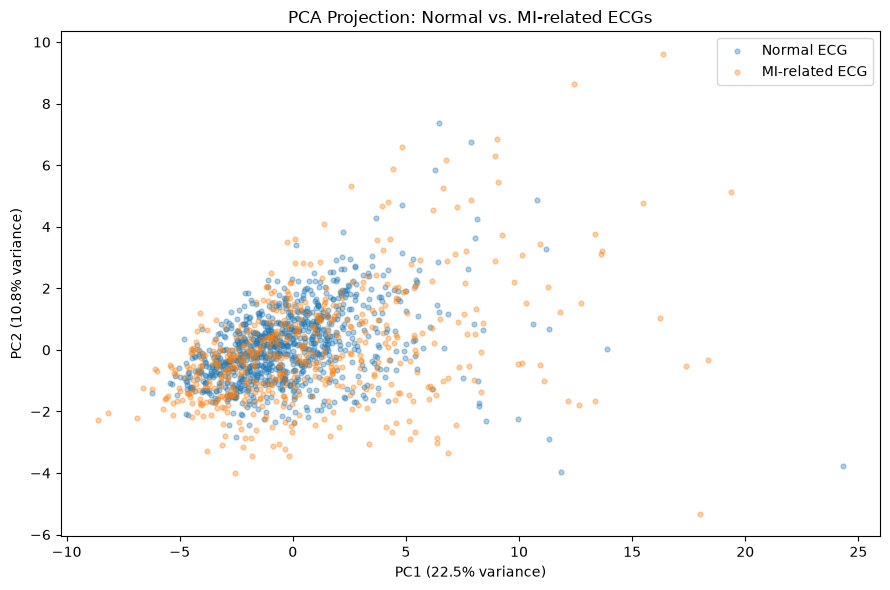

In [8]:
import matplotlib.pyplot as plt

# Using the first two PCs of the validation recordings
pc1 = X_val_full_pca[:, 0]
pc2 = X_val_full_pca[:, 1]

normal_mask = y_binary_val == 0
mi_mask = y_binary_val == 1

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    pc1[normal_mask],
    pc2[normal_mask],
    alpha=0.35,
    s=12,
    label="Normal ECG"
)

ax.scatter(
    pc1[mi_mask],
    pc2[mi_mask],
    alpha=0.35,
    s=12,
    label="MI-related ECG"
)

ax.set_xlabel(
    f"PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}% variance)"
)

ax.set_title("PCA Projection: Normal vs. MI-related ECGs")
ax.legend()

plt.tight_layout()
plt.show()

Here, I can see that normal and MI-related ECGs overlap, and so it is clear that the first two unsupervised componens do not give a clean diagnostic separation, 

## 7. Comparing validation ROC curves and threshold-based metrics 

The ROC curve shows sensitivity against false-positive rate across possible probability thresholds. Here, if AUROC = 0.5, that corresponds to random ranking, and larger values indicate better separation. Therefore, plotting the original-feature and PCA models together shows whether dimensionality reduction changes this tradeoff. 

Here, I also report AUPRC, accuracy, F1, sensitivity, and specificity. Sensitivity measures how many MI recordings are detected, while specificity measures how many normal recordings are correctly rejected. All of these threshold-dependent metrics use 0.5 to stay consistent. 

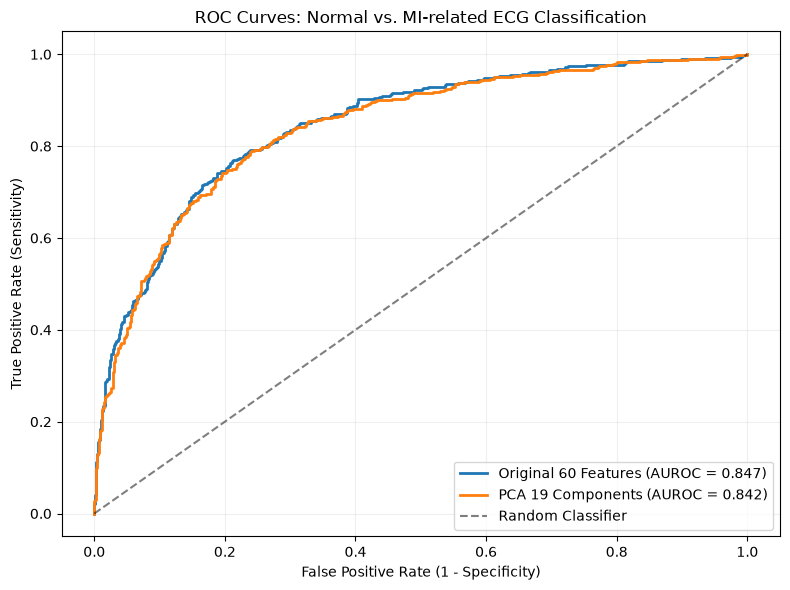

In [9]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Validation probabilities from existing models
probs_original = binary_lr.predict_proba(
    X_binary_val_scaled
)[:, 1]

probs_pca = binary_lr_pca.predict_proba(
    X_binary_val_pca
)[:, 1]

# Calculating ROC curves
fpr_original, tpr_original, _ = roc_curve(
    y_binary_val, probs_original
)

fpr_pca, tpr_pca, _ = roc_curve(
    y_binary_val, probs_pca
)

# Calculating AUROC
auc_original = roc_auc_score(y_binary_val, probs_original)
auc_pca = roc_auc_score(y_binary_val, probs_pca)

# Plot
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr_original,
    tpr_original,
    linewidth=2,
    label=f"Original 60 Features (AUROC = {auc_original:.3f})"
)

ax.plot(
    fpr_pca,
    tpr_pca,
    linewidth=2,
    label=f"PCA 19 Components (AUROC = {auc_pca:.3f})"
)

ax.plot(
    [0, 1], [0, 1],
    "k--",
    alpha=0.5,
    label="Random Classifier"
)

ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_title("ROC Curves: Normal vs. MI-related ECG Classification")

ax.legend(loc="lower right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

def evaluate_binary_model(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "AUROC": roc_auc_score(y_true, probabilities),
        "AUPRC": average_precision_score(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, predictions),
        "F1": f1_score(y_true, predictions),
        "Sensitivity": recall_score(y_true, predictions),
        "Specificity": tn / (tn + fp)
    }

# Evaluating the existing validation predictions
validation_comparison = pd.DataFrame(
    [
        evaluate_binary_model(y_binary_val, probs_original),
        evaluate_binary_model(y_binary_val, probs_pca)
    ],
    index=[
        "Logistic Regression (60 features)",
        "Logistic Regression + PCA (19 PCs)"
    ]
)

display(validation_comparison.round(4))

,AUROC,AUPRC,Accuracy,F1,Sensitivity,Specificity
Logistic Regression (60 features),0.8473,0.7705,0.7806,0.6605,0.5907,0.8880
Logistic Regression + PCA (19 PCs),0.8421,0.7614,0.7779,0.6483,0.5667,0.8974


Both logistic regression models demonstrated similar predictive performance, with the original 60-feature model achieving slightly higher AUROC, AUPRC, accuracy, F1, and sensitivity. Applying PCA reduced the feature space to 19 principal components while producing only a small decrease in overall predictive performance. However, the reduction in sensitivity suggests a tradeoff that may be important in clinical screening applications, where identifying MI-related abnormalities is particularly important.

## 8. Evaluating on the held-out test set 

Now, I will apply the already-fitted scaler, PCA transformation, and classifiers to the test cohort. Since the test set has not been used to fit transformations, choose components, or train the models, it provides a more independent assessment of generalization.

In [11]:
# Extracting ECG features for the held-out binary test cohort
X_binary_test = extract_ecg_features(X[binary_test_idx])
y_binary_test = y_binary[binary_test_idx]

# Applying preprocessing fitted on training data
X_binary_test_scaled = binary_scaler.transform(
    X_binary_test
)

X_binary_test_pca = binary_pca.transform(
    X_binary_test_scaled
)

# Generating test probabilities
test_probs_original = binary_lr.predict_proba(
    X_binary_test_scaled
)[:, 1]

test_probs_pca = binary_lr_pca.predict_proba(
    X_binary_test_pca
)[:, 1]

# Evaluating both models
test_comparison = pd.DataFrame(
    [
        evaluate_binary_model(
            y_binary_test,
            test_probs_original,
            threshold=0.5
        ),
        evaluate_binary_model(
            y_binary_test,
            test_probs_pca,
            threshold=0.5
        )
    ],
    index=[
        "Logistic Regression (60 features)",
        "Logistic Regression + PCA (19 PCs)"
    ]
)

print("Final Held-Out Test Performance")
print("-------------------------------")
print(f"Test recordings: {len(y_binary_test)}")

display(test_comparison.round(4))

Final Held-Out Test Performance
-------------------------------
Test recordings: 1513


,AUROC,AUPRC,Accuracy,F1,Sensitivity,Specificity
Logistic Regression (60 features),0.8306,0.7611,0.7786,0.6557,0.5800,0.8920
Logistic Regression + PCA (19 PCs),0.8136,0.7346,0.7581,0.6250,0.5545,0.8744


Here, the original features logistic regression model achieved an AUROC of 0.8306 and an AUPRC of 0.7611 on the held-out test set, while the PCA-based model achieved an AUROC of 0.8136 and an AUPRC of 0.7346. Both models performed well, with the original features model slightly outperforming the PCA-based model in this binary classification task. 

### Comparing the held-out test ROC curves

Now, I'm going to compare the ROC curves of the two logistic regression models on the held-out test set to assess how well each model distinguishes between normal and MI-related ECGs across different classification thresholds.

These curves summarize the final discrimination of the two approaches across thresholds. The gap between the curves should be interpreted alongside the numerical AUROC difference rather than judged only by visual overlap.

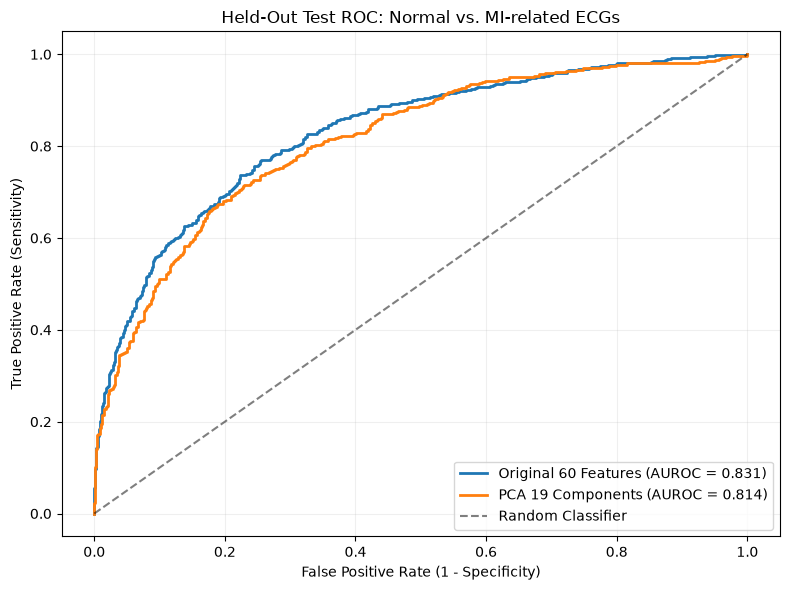

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ROC curves on held-out test data
fpr_original, tpr_original, _ = roc_curve(
    y_binary_test, test_probs_original
)

fpr_pca, tpr_pca, _ = roc_curve(
    y_binary_test, test_probs_pca
)

# Test AUROC
auc_original = roc_auc_score(
    y_binary_test, test_probs_original
)

auc_pca = roc_auc_score(
    y_binary_test, test_probs_pca
)

# Plot
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr_original,
    tpr_original,
    linewidth=2,
    label=f"Original 60 Features (AUROC = {auc_original:.3f})"
)

ax.plot(
    fpr_pca,
    tpr_pca,
    linewidth=2,
    label=f"PCA 19 Components (AUROC = {auc_pca:.3f})"
)

ax.plot(
    [0, 1], [0, 1],
    "k--",
    alpha=0.5,
    label="Random Classifier"
)

ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_title(
    "Held-Out Test ROC: Normal vs. MI-related ECGs"
)

ax.legend(loc="lower right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Overall conclusions 

These results suggest that logistic regression can distinguish normal from MI-related ECGs with reasonable, but imperfect, predictive performance. The original 60-feature model achieved a test AUROC of 0.8305 and accuracy of 0.7779. However, its sensitivity of 0.5800 indicates that a substantial proportion of MI-labeled ECGs were missed at the 0.5 classification threshold, highlighting an important limitation for potential clinical screening applications.

PCA preserved much of the predictive performance while substantially reducing dimensionality. Using 19 principal components, which explained 95.08% of the training feature variance, reduced the number of predictors by 68.3%, with only a modest decrease in test AUROC from 0.8305 to 0.8136. Validation results also suggested that much of the predictive information was captured within approximately 10–19 principal components. Although PC1 and PC2 showed substantial overlap between normal and MI-related ECGs, the overall results suggest that useful predictive information is distributed across multiple dimensions.

It could be useful to try multilabel logistic regression. Since ECG recordings can exhibit multiple abnormalities simultaneously, extending the binary classification framework to predict multiple diagnostic categories could better capture the complexity of ECG data. This would also allow us to investigate which ECG-derived features are associated with different cardiac abnormalities while maintaining model interpretability.